In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from fredapi import Fred 

calibration - estimating unknown paramters using parameter estimation

parameter estimation - OLS MLE GMM Kalman Fiter

In [ ]:
API_KEY = "johndoe"

fred = Fred(api_key=API_KEY)
US10Y = fred.get_series("GS10", observation_start="2000-01-01")
US02Y = fred.get_series("GS2", observation_start="2000-01-01")

df = pd.DataFrame({"US10Y" : US10Y, "US02Y" : US02Y})
df["Spread"] = df["US10Y"] - df["US02Y"]

print(df.head(5))

            US10Y  US02Y  Spread
2000-01-01   6.66   6.44    0.22
2000-02-01   6.52   6.61   -0.09
2000-03-01   6.26   6.53   -0.27
2000-04-01   5.99   6.40   -0.41
2000-05-01   6.44   6.81   -0.37


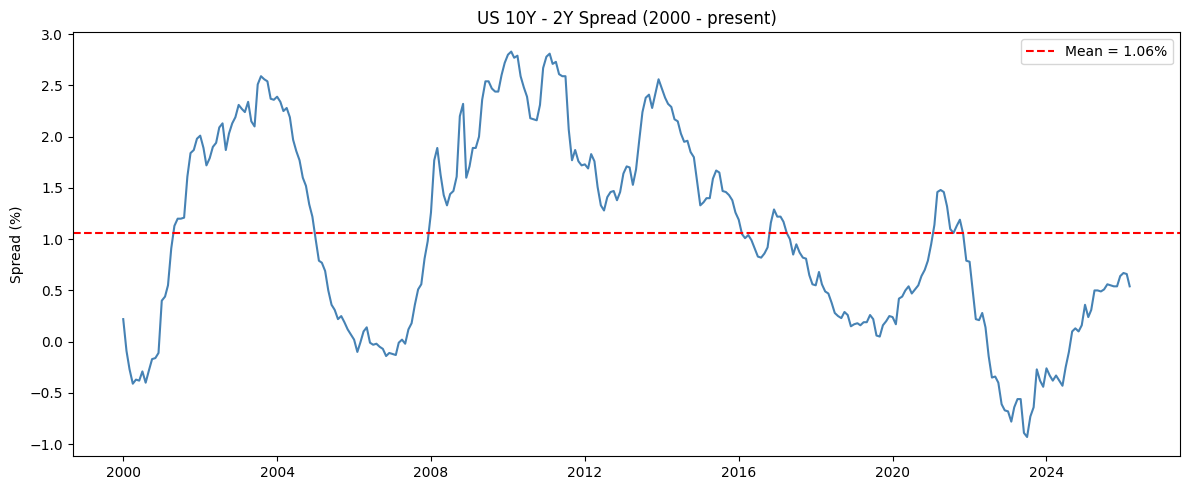

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(df["Spread"], color="steelblue")
plt.axhline(df["Spread"].mean(), color="red", linestyle="--", label=f"Mean = {df['Spread'].mean():.2f}%")
plt.title("US 10Y - 2Y Spread (2000 - present)")
plt.ylabel("Spread (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
df["Spread_Lag"] = df["Spread"].shift(1)
df = df.dropna()

print(df.head())



            US10Y  US02Y  Spread  Spread_Lag
2000-02-01   6.52   6.61   -0.09        0.22
2000-03-01   6.26   6.53   -0.27       -0.09
2000-04-01   5.99   6.40   -0.41       -0.27
2000-05-01   6.44   6.81   -0.37       -0.41
2000-06-01   6.10   6.48   -0.38       -0.37


In [5]:
X = sm.add_constant(df["Spread_Lag"])
Y = df["Spread"]

model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Spread   R-squared:                       0.977
Model:                            OLS   Adj. R-squared:                  0.977
Method:                 Least Squares   F-statistic:                 1.321e+04
Date:                Sat, 18 Apr 2026   Prob (F-statistic):          1.91e-257
Time:                        17:30:42   Log-Likelihood:                 157.26
No. Observations:                 314   AIC:                            -310.5
Df Residuals:                     312   BIC:                            -303.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0141      0.012      1.144      0.2

In [6]:
alpha = model.params["const"]
beta = model.params["Spread_Lag"]
T = len(df)          
dt = 1/12      

kappa = (1 - beta) / dt
theta = alpha / (1 - beta)
sigma = model.resid.std() / (dt ** 0.5)

print(f"Kappa (κ): {kappa:.4f}")
print(f"Theta (θ): {theta:.4f}")
print(f"Sigma (σ): {sigma:.4f}")

Kappa (κ): 0.1480
Theta (θ): 1.1423
Sigma (σ): 0.5088


In [7]:
half_life = np.log(2) / kappa
print(f"Half-life: {half_life:.2f} months = {half_life/12:.2f} years")

Half-life: 4.68 months = 0.39 years


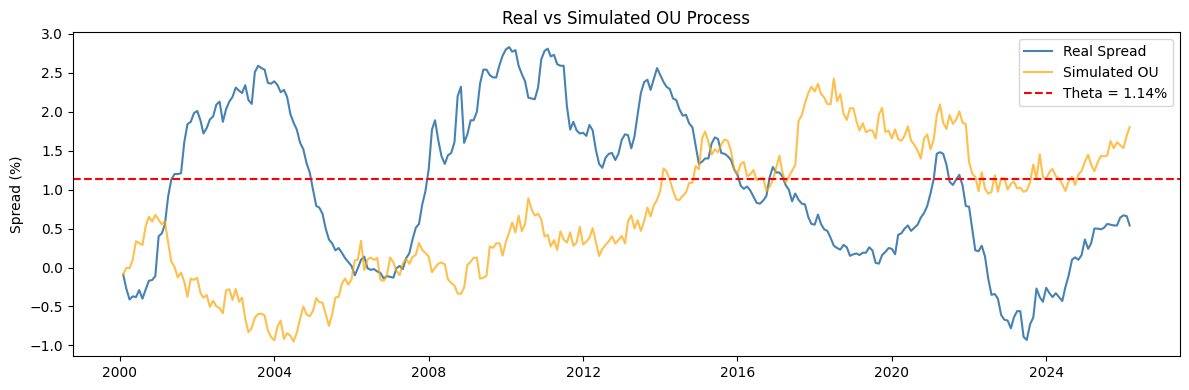

In [8]:
np.random.seed(42)
 
X = np.zeros(T)
X[0] = df["Spread"].iloc[0]

for t in range(1, T):
    dW = np.random.normal(0, np.sqrt(dt))
    X[t] = X[t-1] + kappa * (theta - X[t-1]) * dt + sigma * dW


plt.figure(figsize=(12, 4))
plt.plot(df.index, df["Spread"], color="steelblue", label="Real Spread")
plt.plot(df.index, X, color="orange", alpha=0.7, label="Simulated OU")
plt.axhline(theta, color="red", linestyle="--", label=f"Theta = {theta:.2f}%")
plt.title("Real vs Simulated OU Process")
plt.ylabel("Spread (%)")
plt.legend()
plt.tight_layout()
plt.show()

OU Simulation       - Model explain how the data behave and verify those parameters
θ, κ, σ, half-life  - these output will be used as benchmark

To verify if the simulated OU and data behave the same we use statistics

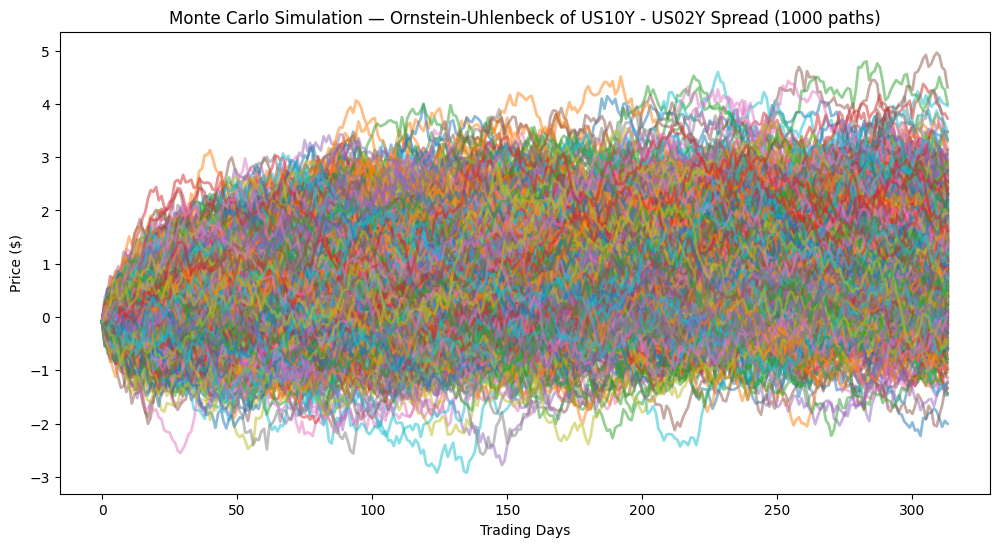

In [12]:
n_simulations = 1000

all_simulations = []

for i in range(n_simulations):
    X = np.zeros(T)
    X[0] = df["Spread"].iloc[0]
    
    for t in range(1, T):
        dW = np.random.normal(0, np.sqrt(dt))
        X[t] = X[t-1] + kappa * (theta - X[t-1]) * dt + sigma * dW
    
    all_simulations.append(X)
all_simulations = np.array(all_simulations)


plt.figure(figsize=(12,6))
for path in all_simulations:
    plt.plot(path, alpha=0.5, linewidth = 2.0)

plt.title("Monte Carlo Simulation — Ornstein-Uhlenbeck of US10Y - US02Y Spread (1000 paths)")
plt.xlabel("Trading Days")
plt.ylabel("Price ($)")
plt.show()

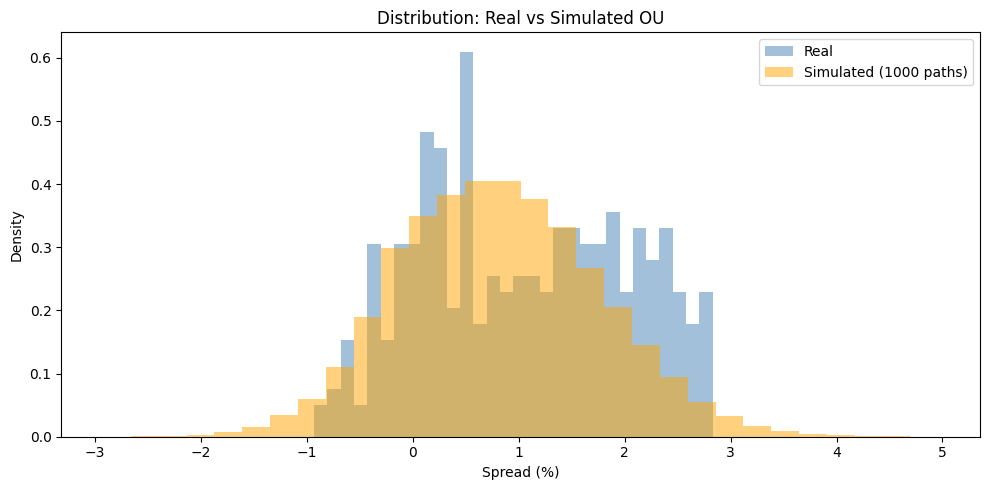

In [15]:
plt.figure(figsize=(10, 5))
plt.hist(df["Spread"], bins=30, alpha=0.5, label="Real", color="steelblue", density=True)
plt.hist(all_simulations.flatten(), bins=30, alpha=0.5, label="Simulated (1000 paths)", color="orange", density=True)
plt.title("Distribution: Real vs Simulated OU")
plt.xlabel("Spread (%)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
adf_pvalues = []

for path in all_simulations:
    pvalue = adfuller(path)[1]
    adf_pvalues.append(pvalue)

adf_real = adfuller(df["Spread"])
adf_simul_mean = np.mean(adf_pvalues)

print(f"Real      - p-value: {adf_real[1]:.4f}")
print(f"Simulated - p-value: {adf_simul_mean:.4f}")

Real      - p-value: 0.0204
Simulated - p-value: 0.3279
